# SAXS asymmetry — methods investigated by mechanism

Part of **HRXP** (Hibef ReLaX XFEL Propagator, GPL-3). This notebook applies the corrected
`PCI.py` forward model to each proposed source of SAXS left/right asymmetry.

The two observable branches deliberately follow their clean reference notebooks:

- **PCI image:** the divergent `PCI.gaussian_XFEL` source and voxelized `PCI.py`
  wire transmission on a 4096×4096, 8 nm grid, evaluated immediately after
  the sample without detector propagation.
- **SAXS image:** `clean_saxs_design.ipynb` — voxelized `PCI.wire` and the package's
  Lorentz/Fresnel propagation on an 4096×4096, 8 nm grid to the detector 1.31 m after the sample.


**Methods investigated** (each numbered item has a matching section):

| # | Mechanism / method | Knob and configuration point | Observable / expected signature |
|---|---|---|---|
| 1 | Wire transverse offset in a divergent beam | Configured target FWHM plus Mark1300's 2-row/central-mask extraction | horizontal Q$_x$ SAXS calibration compared with Mark1300 |
| 2 | Divergence / spot-size dependence | `DIV_CASES`, `DIV_OFFSETS` → `run_sim(waist_nm=…)` | calibration slope versus divergence |
| 3 | PCI-exit + SAXS-detector gallery | `MOVIE_OFFSETS_UM`, `SAVE_TIFS` in the Method 3 cell | direct post-sample PCI and propagated SAXS TIFs and offset GIF |



In [6]:

import pickle, sys, time
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import interpolate
from scipy.ndimage import shift as nd_shift

ANALYSIS_DIR = Path.cwd()
if not (ANALYSIS_DIR / "PCI.py").exists():
    ANALYSIS_DIR = ANALYSIS_DIR / "SAXS_asymmetry"
if not (ANALYSIS_DIR / "PCI.py").exists():
    raise FileNotFoundError("run from the repository root or SAXS_asymmetry/")
if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))
import PCI
import rossendorfer_farbenliste as rofl # for color palette

INPUT_DIR = ANALYSIS_DIR / "inputs"
OUTPUT_DIR = ANALYSIS_DIR / "outputs"
CACHE_DIR = ANALYSIS_DIR / "cache"
METHODS_OUTPUT_DIR = OUTPUT_DIR / "methods"
FIG_DIR = METHODS_OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_T0 = time.perf_counter()
plt.rcParams["figure.facecolor"] = "w"

# SAXS configuration: 
# N_GRID and PIXEL_SIZE sample the complex field at the source/sample plane;
# together they set the real-space field of view and the reciprocal-space sampling.
N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
PHOTON_ENERGY = 8.2 * PCI.keV
LAMBDA_NM = PCI.HC_KEV_NM / PHOTON_ENERGY  # X-ray wavelength lambda [nm]
Z_TARGET = 0.25 * PCI.m   # distance from the Gaussian waist plane to the wire
Z_DETECTOR = 1.31 * PCI.m  # free-space distance from the wire to the SAXS detector

# TARGET_FWHM is the full width at half maximum of intensity at the wire.
# TARGET_BEAM_RADIUS is w(z): the 1/e field-amplitude radius, equivalently
# the 1/e^2 intensity radius used by the Gaussian-beam formulas in the docs.
TARGET_FWHM = 6.00 * PCI.um  # intensity FWHM at the target
FWHM_TAG = f"{TARGET_FWHM / PCI.um:g}".replace(".", "p")
TARGET_BEAM_RADIUS = TARGET_FWHM / np.sqrt(2 * np.log(2))

# Gaussian spreading obeys w(z)^2 = w0^2 + [lambda*z/(pi*w0)]^2.
# DIFFRACTION_TERM = lambda*z/pi therefore has units of length squared and
# measures how strongly diffraction broadens a waist over Z_TARGET.
DIFFRACTION_TERM = LAMBDA_NM * Z_TARGET / np.pi
# Solve the quadratic in w0^2 and take the smaller root: SOURCE_WAIST is
# the source-plane 1/e^2-intensity radius, not a FWHM or target-plane size.
SOURCE_WAIST = np.sqrt(                                              
    (TARGET_BEAM_RADIUS**2
     - np.sqrt(TARGET_BEAM_RADIUS**4 - 4 * DIFFRACTION_TERM**2)) / 2
)
WIRE_RADIUS = 5 * PCI.um  # physical Cu-wire radius in the projected target
VOXEL_SIZE = 20 * PCI.nm  # sampling of the wire-thickness map before interpolation
VOXEL_NUMBER = 2000       # transverse extent of that target map in voxels
OFFSET_SCAN_UM = np.arange(-10.0, 10.0 + 1.25, 2.5)  # wire motion; beam stays centered
Q_MAX = np.pi / PIXEL_SIZE  # Nyquist momentum transfer of the sample-plane grid
Q_AXIS = np.linspace(-Q_MAX, Q_MAX, N_GRID)
DQ = 2 * np.pi / (N_GRID * PIXEL_SIZE)  # reciprocal-space bin width
MARK1300_Q_MIN = 0.10
MARK1300_CENTER_HALF_WIDTH_PIXELS = int(np.round(MARK1300_Q_MIN / DQ))

def source_waist_for_target_fwhm(fwhm_nm, divergent=True):
    """Infer source-plane Gaussian radius w0 from an intensity FWHM at the wire.

    The smaller quadratic root is the strongly divergent, small-waist branch;
    the larger root is the broad-waist, weakly divergent branch.
    """
    radius = fwhm_nm / np.sqrt(2 * np.log(2))  # target-plane w(z), not w0
    term = LAMBDA_NM * Z_TARGET / np.pi        # lambda*z/pi [length^2]
    disc = radius**4 - 4 * term**2
    if disc < 0:
        raise ValueError("requested FWHM is below the diffraction limit")
    sign = -1 if divergent else 1  # choose smaller or larger solution for w0^2
    return np.sqrt((radius**2 + sign * np.sqrt(disc)) / 2)

WAIST_DEFAULT = SOURCE_WAIST
# These values hold the requested target-plane FWHM fixed per case while
# changing source waist, Rayleigh range, wavefront curvature, and divergence.
WAIST_FOR_TARGET_FWHM = {
    value: source_waist_for_target_fwhm(value * PCI.um)
    for value in (9, 12)
}
# The larger root gives a large w0 and hence theta ~= lambda/(pi*w0) is small.
WAIST_COLLIMATED = source_waist_for_target_fwhm(12 * PCI.um, divergent=False)

RUN_FILES = {
    run: INPUT_DIR / "experimental" / "SAXSData" / f"profiles_cleaned_p3129_{run}.pickle"
    for run in ("r0528", "r0534", "r0546")
}
POINTING_RUN_SCALES = {"r0528": 50e3, "r0534": 80e3, "r0546": 80e3}
POINTING_EXPERIMENTAL = {}
for run, path in RUN_FILES.items():
    with path.open("rb") as stream:
        experimental = pickle.load(stream)
    experimental = [np.nan_to_num(np.asarray(values), nan=0.0) for values in experimental]
    q_values = np.concatenate((np.flip(-experimental[0])[:-1], experimental[0]))
    exp_lineout = np.concatenate((np.flip(experimental[1])[:-1], experimental[2]))
    POINTING_EXPERIMENTAL[run] = (
        q_values, exp_lineout / exp_lineout.max() / POINTING_RUN_SCALES[run]
    )
POINTING_Q_AXIS = POINTING_EXPERIMENTAL["r0528"][0]
erik_pos_nm = np.load(INPUT_DIR / "experimental" / "Erik" / "pos_grid.npy").astype(float)
erik_l_over_r = np.load(INPUT_DIR / "experimental" / "Erik" / "left_div_right.npy")
exp_motor_um = np.load(INPUT_DIR / "experimental" / "Erik" / "motor_positions_um.npy")
exp_left_frac = np.load(INPUT_DIR / "experimental" / "Erik" / "left_div_left_right_exp.npy")
erik_left_frac = erik_l_over_r / (1 + erik_l_over_r)
mark1300 = np.loadtxt(OUTPUT_DIR / "saxs" / "tables" / "DivSAXS_asymmetry_Mark1300_6um_lg.dat")
mark_offset_um = mark1300[:, 0] / 1e3
mark_left_frac = mark1300[:, 1] / (mark1300[:, 1] + mark1300[:, 2])

class projected_wire(PCI.wire):
    """Memory-efficient 2-D equivalent of PCI.wire's voxel projection."""
    def _get_projection(self, volume=None):
        transverse_px = np.arange(self.voxel_number) - self.voxel_number // 2
        radius_px = self.radius1_nm / self.voxel_size
        inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
        profile = np.where(
            np.abs(transverse_px) <= radius_px,
            (2 * np.floor(np.sqrt(inside)) + 1) * self.voxel_size,
            0.0,
        )[None, :]
        projection = np.broadcast_to(profile, (self.voxel_number, self.voxel_number)).copy()
        self._density1 = nd_shift(
            projection,
            np.asarray(self.position_xy) / self.voxel_size,
            order=1, mode="constant", cval=0, prefilter=False,
        )
        return self._density1

def pci_exit_intensity(wire_offset_um):
    """Return intensity immediately after the shifted wire; do not propagate."""
    target = projected_wire(
        "wire",
        photon_Energy=PHOTON_ENERGY, radius=WIRE_RADIUS, material=PCI.Cu,
        position=[0, wire_offset_um * PCI.um, Z_TARGET],
        voxel_size=VOXEL_SIZE, voxel_number=VOXEL_NUMBER,
    )
    xfel = PCI.gaussian_XFEL(
        waist=SOURCE_WAIST, pixel_number=N_GRID, pixel_size=PIXEL_SIZE,
        photon_energy=PHOTON_ENERGY, photon_energy_bandwidth=0 * PCI.eV,
        photon_energy_bandwidth_sample_width=0 * PCI.eV,
    )
    incident = xfel.initialize_to_position(Z_TARGET, reset=False)
    exit_field = xfel.propagate_through_target(
        target, reset=False, field_in=incident, photon_energy=PHOTON_ENERGY,
    )

    return np.abs(exit_field)**2

# V2 caches are configuration-specific and never import generic gallery TIFFs.
OFFSET_CACHE_DIR = CACHE_DIR / "methods" / (
    f"Method1CacheV2_N{N_GRID}_Pix{PIXEL_SIZE:g}nm_"
    f"FWHM{TARGET_FWHM / PCI.um:g}um_Mark{MARK1300_CENTER_HALF_WIDTH_PIXELS}"
)
OFFSET_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def record_from_saxs_intensity(
    intensity, *, offset_um=0.0, wall_s=0.0, keep_image=False,
):
    center = intensity.shape[0] // 2
    lineout = intensity[center - 5:center + 5].mean(axis=0)
    mark1300_lineout = intensity[center - 1:center + 1].mean(axis=0)
    mark1300_left = float(
        mark1300_lineout[:center - MARK1300_CENTER_HALF_WIDTH_PIXELS].sum()
    )
    mark1300_right = float(
        mark1300_lineout[center + MARK1300_CENTER_HALF_WIDTH_PIXELS:].sum()
    )
    mark1300_frac = mark1300_left / (mark1300_left + mark1300_right)
    pointing_lineout = interpolate.interp1d(
        Q_AXIS, lineout, fill_value="extrapolate"
    )(POINTING_Q_AXIS)
    pointing_lineout = pointing_lineout / pointing_lineout.max() * 2
    record = dict(
        offset_um=float(offset_um),
        mark1300_left=mark1300_left, mark1300_right=mark1300_right,
        mark1300_frac=mark1300_frac,
        pointing_lineout=pointing_lineout.astype(np.float32), wall_s=float(wall_s),
    )
    if keep_image:
        record["saxs_detector_intensity"] = intensity
    return record

def offset_cache_path(offset_um):
    tag = f"{float(offset_um):+.2f}".replace("+", "p").replace("-", "m").replace(".", "p")
    return OFFSET_CACHE_DIR / f"offset_{tag}um.pickle"

def record_from_saxs_tif(path, offset_um):
    t0 = time.perf_counter()
    with Image.open(path) as image:
        intensity = np.asarray(image, dtype=np.float32)
    if intensity.shape != (N_GRID, N_GRID):
        raise ValueError(f"cached detector image has shape {intensity.shape}")
    return record_from_saxs_intensity(
        intensity, offset_um=offset_um, wall_s=time.perf_counter() - t0,
    )

def saxs_tif_matches_current_grid(path):
    with Image.open(path) as image:
        return image.size == (N_GRID, N_GRID)

def run_sim(offset_um=0.0, waist_nm=WAIST_DEFAULT, keep_image=False):
    t0 = time.perf_counter()
    target = projected_wire(
        "wire",
        radius=WIRE_RADIUS, photon_Energy=PHOTON_ENERGY, material=PCI.Cu,
        position=[0, offset_um * PCI.um, Z_TARGET],
        voxel_size=VOXEL_SIZE, voxel_number=VOXEL_NUMBER,
    )
    xfel = PCI.gaussian_XFEL(
        waist=waist_nm, pixel_number=N_GRID, pixel_size=PIXEL_SIZE,
        photon_energy=PHOTON_ENERGY, photon_energy_bandwidth=0 * PCI.eV,
        photon_energy_bandwidth_sample_width=0 * PCI.eV,
    )
    detector = PCI.jungfrau(
        "SAXS", category="SAXS", XFEL=xfel,
        position=[0, 0, Z_TARGET + Z_DETECTOR],
    )
    PCI.Beamline(target=target, XFEL=xfel, detector=detector).propagate_XFEL_to(
        detector=detector
    )
    intensity = xfel.intensity_detector
    return record_from_saxs_intensity(
        intensity, offset_um=offset_um, wall_s=time.perf_counter() - t0,
        keep_image=keep_image,
    )

def run_scan(param_dicts, label):
    records = []
    for index, params in enumerate(param_dicts, 1):
        cache_path = None
        record = None
        if label == "offset" and set(params) == {"offset_um"}:
            offset_um = float(params["offset_um"])
            cache_path = offset_cache_path(offset_um)
            if cache_path.exists():
                with cache_path.open("rb") as stream:
                    record = pickle.load(stream)
                print(f"[{label} {index}/{len(param_dicts)}] loaded {cache_path.name}")
            if record is None and abs(offset_um) < 1e-12 and "baseline" in globals():
                record = dict(baseline)
                print(f"[{label} {index}/{len(param_dicts)}] reused centered baseline")
            if record is None:
                tif_path = METHODS_OUTPUT_DIR / "movie" / f"{FWHM_TAG}um" / (
                    f"DivSAXS_Offset{offset_um:.2f}um.tif"
                )
                if tif_path.exists() and saxs_tif_matches_current_grid(tif_path):
                    record = record_from_saxs_tif(tif_path, offset_um)
                    print(f"[{label} {index}/{len(param_dicts)}] reused {tif_path.name}")
        if record is None:
            print(
                f"[{label} {index}/{len(param_dicts)}] starting propagation {params}",
                flush=True,
            )
            record = run_sim(**params)
        if cache_path is not None and not cache_path.exists():
            with cache_path.open("wb") as stream:
                pickle.dump(record, stream, protocol=pickle.HIGHEST_PROTOCOL)
        records.append(record)
        print(f"[{label} {index}/{len(param_dicts)}] {params}: "
              f"Mark1300 L/(L+R)={record['mark1300_frac']:.4f}, "
              f"{record['wall_s']:.1f} s")
    return records

RESULTS = {}
baseline_cache = offset_cache_path(0.0)
if baseline_cache.exists():
    with baseline_cache.open("rb") as stream:
        baseline = pickle.load(stream)
    print(f"Loaded centered baseline from {baseline_cache.name}")
else:
    baseline = run_sim()
    with baseline_cache.open("wb") as stream:
        pickle.dump(baseline, stream, protocol=pickle.HIGHEST_PROTOCOL)
RESULTS["baseline"] = [baseline]
print(f"SAXS: {N_GRID}^2, waist {SOURCE_WAIST / PCI.um:.6f} um, "
      f"target FWHM {TARGET_FWHM / PCI.um:g} um, detector {Z_DETECTOR / PCI.m:g} m")
print(f"PCI: {N_GRID}^2, {PIXEL_SIZE:g} nm, immediately after sample")


Loaded centered baseline from offset_p0p00um.pickle
SAXS: 4096^2, waist 2.846721 um, target FWHM 6 um, detector 1.31 m
PCI: 4096^2, 8 nm, immediately after sample


## Experimental reference data

The cleaned profiles are reconstructed as `clean_saxs_design.ipynb` does: NaNs become zero,
signed q is rebuilt, and simulated lineouts are interpolated onto the run-528 q grid.

* `inputs/experimental/SAXSData/profiles_cleaned_p3129_r05{28,34,46}.pickle` — cleaned aggregate 1-D profiles
  `(q_positive, left, right)` of EuXFEL proposal p3129;
* `inputs/experimental/Erik/` — collimated-beam simulation (`pos_grid`, `left_div_right`, `left_plus_right`) and the
  experimental motor scan (`motor_positions_um`, `left_div_left_right_exp`);
* `outputs/saxs/tables/DivSAXS_asymmetry_Mark1300_6um.dat` — archived divergent-beam asymmetry table
  (offset nm, left, right) produced by the legacy TIF pipeline.


## Method 1 — wire transverse offset in a divergent beam

The legacy mechanism: the wire is displaced across the divergent beam, so it samples a locally
tilted (curved) wavefront and the SAXS streak develops a left/right imbalance. This section
keeps the configured source, grid, propagation, 10-row displayed lineouts, experimental q grid,
normalization, and plotting scale from `clean_saxs_design.ipynb`. For the L/(L+R) comparison
only, it reproduces Mark1300's two-row lineout and excludes the central ±1040 pixels
(approximately |q| < 0.10 nm⁻¹), then compares against

* the archived divergent-beam table (`Mark1300`, TIF pipeline / obsolete code),
* Erik's collimated-beam simulation, and
* the experimental motor scan.

Sign note: the legacy TIFs were produced by the obsolete module whose offset shifted the wire
along the *wrong* axis (see `PCI.py` header). Agreement is therefore expected up to a possible
mirror flip of the offset axis, which is checked numerically below.

The optional image gallery in method 5 reuses this geometry. PCI and SAXS are each
propagated independently with the method and grid used in their clean reference notebook.


In [7]:
RESULTS["offset"] = run_scan(
    [dict(offset_um=o) for o in OFFSET_SCAN_UM], label="offset")


[offset 1/9] loaded offset_m10p00um.pickle
[offset 1/9] {'offset_um': np.float64(-10.0)}: Mark1300 L/(L+R)=0.2100, 6.8 s
[offset 2/9] loaded offset_m7p50um.pickle
[offset 2/9] {'offset_um': np.float64(-7.5)}: Mark1300 L/(L+R)=0.2192, 6.9 s
[offset 3/9] loaded offset_m5p00um.pickle
[offset 3/9] {'offset_um': np.float64(-5.0)}: Mark1300 L/(L+R)=0.2363, 6.8 s
[offset 4/9] loaded offset_m2p50um.pickle
[offset 4/9] {'offset_um': np.float64(-2.5)}: Mark1300 L/(L+R)=0.2837, 6.8 s
[offset 5/9] loaded offset_p0p00um.pickle
[offset 5/9] {'offset_um': np.float64(0.0)}: Mark1300 L/(L+R)=0.4984, 7.2 s
[offset 6/9] loaded offset_p2p50um.pickle
[offset 6/9] {'offset_um': np.float64(2.5)}: Mark1300 L/(L+R)=0.7131, 7.4 s
[offset 7/9] loaded offset_p5p00um.pickle
[offset 7/9] {'offset_um': np.float64(5.0)}: Mark1300 L/(L+R)=0.7606, 7.9 s
[offset 8/9] loaded offset_p7p50um.pickle
[offset 8/9] {'offset_um': np.float64(7.5)}: Mark1300 L/(L+R)=0.7778, 8.4 s
[offset 9/9] loaded offset_p10p00um.pickle
[offset

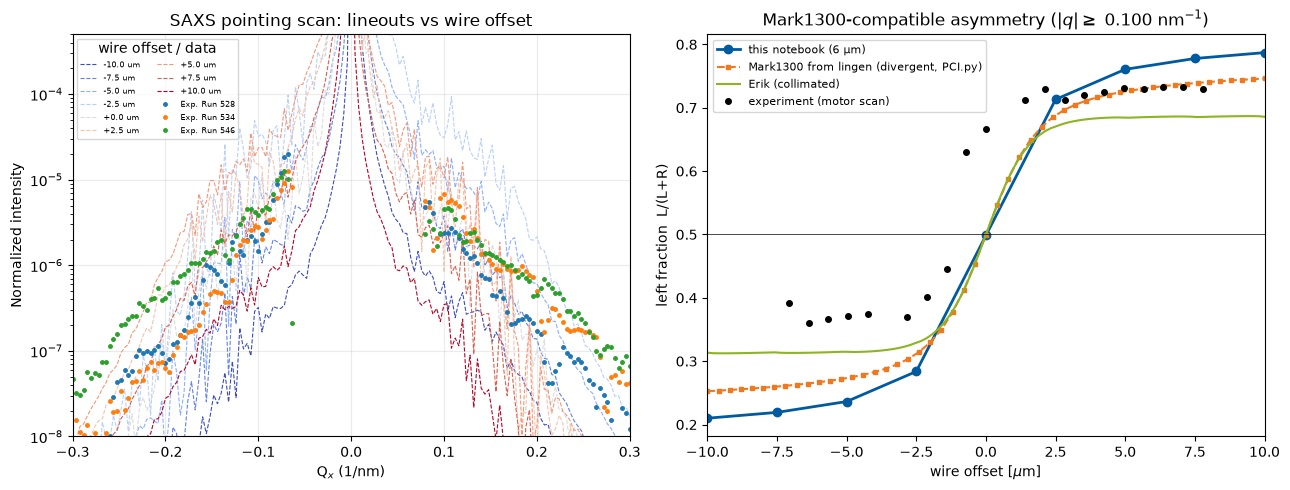

Mark1300 extraction: 2 rows, ±522 center pixels excluded (|q| < 0.1000 1/nm)
calibration slope d[L/(L+R)]/d(offset): 6 um model +0.0364 /um, Mark1300 archive +0.0338 /um
=> same sign


In [8]:
off_um = np.array([r["offset_um"] for r in RESULTS["offset"]])
off_frac = np.array([r["mark1300_frac"] for r in RESULTS["offset"]])

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
cmap = plt.cm.coolwarm
for rec in RESULTS["offset"]:
    axs[0].semilogy(POINTING_Q_AXIS, rec["pointing_lineout"], "--",
                    color=cmap((rec["offset_um"] - off_um.min()) / np.ptp(off_um)),
                    lw=0.8, label=f"{rec['offset_um']:+.1f} um")
for run, (q_values, exp_lineout) in POINTING_EXPERIMENTAL.items():
    axs[0].semilogy(q_values, exp_lineout, "o", markersize=2.5,
                    label=f"Exp. Run {int(run[1:])}")
axs[0].set_xlim(-0.3, 0.3)
axs[0].set_ylim(1e-8, 5e-4)
axs[0].set_xlabel(r"Q$_x$ (1/nm)")
axs[0].set_ylabel("Normalized intensity")
axs[0].grid(alpha=0.25)
axs[0].legend(fontsize=6, ncol=2, title="wire offset / data")
axs[0].set_title("SAXS pointing scan: lineouts vs wire offset")

axs[1].plot(off_um, off_frac, "o-", color=rofl.b(), lw=2,
            label=f"this notebook ({TARGET_FWHM / PCI.um:g} µm)")
axs[1].plot(mark_offset_um, mark_left_frac, "s--", ms=3, color=rofl.o(),
            label="Mark1300 from lingen (divergent, PCI.py)")
axs[1].plot(erik_pos_nm / 1e3, erik_left_frac, "-", color=rofl.g(),
            label="Erik (collimated)")
axs[1].plot(exp_motor_um, exp_left_frac, "ko", ms=4, label="experiment (motor scan)")
axs[1].axhline(0.5, color="k", lw=0.5)
axs[1].set_xlabel(r"wire offset [$\mu$m]")
axs[1].set_ylabel("left fraction  L/(L+R)")
axs[1].set_xlim(-10, 10)
axs[1].legend(fontsize=8, loc="upper left")
axs[1].set_title(
    fr"Mark1300-compatible asymmetry ($|q| \geq$ {MARK1300_Q_MIN:.3f} nm$^{{-1}}$)"
)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_offset_scan.png", dpi=200, bbox_inches="tight")
plt.show()

# Persist in the legacy 3-column format under outputs/methods/tables/.
table = np.column_stack([off_um * 1e3,
                         [r["mark1300_left"] for r in RESULTS["offset"]],
                         [r["mark1300_right"] for r in RESULTS["offset"]]])
methods_table_path = METHODS_OUTPUT_DIR / "tables" / f"DivSAXS_asymmetry_Methods_{FWHM_TAG}um.dat"
methods_table_path.parent.mkdir(parents=True, exist_ok=True)
np.savetxt(methods_table_path, table)

slope_new = np.polyfit(off_um, off_frac, 1)[0]
slope_mark = np.polyfit(mark_offset_um, mark_left_frac, 1)[0]
print(f"Mark1300 extraction: 2 rows, ±{MARK1300_CENTER_HALF_WIDTH_PIXELS} center pixels "
      f"excluded (|q| < {MARK1300_Q_MIN:.4f} 1/nm)")
print(f"calibration slope d[L/(L+R)]/d(offset): {TARGET_FWHM / PCI.um:g} um model {slope_new:+.4f} /um, "
      f"Mark1300 archive {slope_mark:+.4f} /um")
print("=> same sign" if np.sign(slope_new) == np.sign(slope_mark)
      else "=> opposite sign: the archived axis is mirrored (known obsolete-code axis bug)")


## Method 2 — divergence dependence of the offset calibration

Lingen's note in the legacy notebook ("the SAXS signal is affected a lot by the XFEL beam
divergence") made divergence the prime suspect. Here the wire-offset scan is repeated for
different Gaussian source waists. On the smaller-root branch, a larger on-target FWHM at fixed
0.25 m corresponds to a smaller source waist and therefore *larger* far-field divergence; the
separate larger-root case is quasi-collimated. If offset-induced asymmetry is a
wavefront-curvature effect, the calibration slope
d[L/(L+R)]/d(offset) must shrink toward zero as the beam becomes collimated — which is also why
Erik's collimated simulation needs much larger offsets for the same asymmetry.


[div 9 um FWHM 1/11] starting propagation {'offset_um': np.float64(-10.0), 'waist_nm': np.float64(1610.2158661968588)}
Rayleigh [m]:  0.0538723094217001
Radius [um]:  261608.9028897096 0.15120024068359483
the beam waist on the target plane is  7.644 um
the FWHM beam waist on the target plane is  9.000 um
the target postion is 0.250 m
complex q parameter is (250000000.00000003+53872309.42170011j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


[div 9 um FWHM 1/11] {'offset_um': np.float64(-10.0), 'waist_nm': np.float64(1610.2158661968588)}: Mark1300 L/(L+R)=0.2161, 9.0 s
[div 9 um FWHM 2/11] starting propagation {'offset_um': np.float64(-8.0), 'waist_nm': np.float64(1610.2158661968588)}
Rayleigh [m]:  0.0538723094217001
Radius [um]:  261608.9028897096 0.15120024068359483
the beam waist on the target plane is  7.644 um
the FWHM beam waist on the target plane is  9.000 um
the target postion is 0.250 m
complex q parameter is (250000000.00000003+53872309.42170011j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


[div 9 um FWHM 2/11] {'offset_um': np.float64(-8.0), 'waist_nm': np.float64(1610.2158661968588)}: Mark1300 L/(L+R)=0.2274, 7.9 s
[div 9 um FWHM 3/11] starting propagation {'offset_um': np.float64(-6.0), 'waist_nm': np.float64(1610.2158661968588)}
Rayleigh [m]:  0.0538723094217001
Radius [um]:  261608.9028897096 0.15120024068359483
the beam waist on the target plane is  7.644 um
the FWHM beam waist on the target plane is  9.000 um
the target postion is 0.250 m
complex q parameter is (250000000.00000003+53872309.42170011j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


... (57 outputs left out)

"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


[div collimated 10/11] {'offset_um': np.float64(8.0), 'waist_nm': np.float64(10122.306785889903)}: Mark1300 L/(L+R)=0.7308, 8.2 s
[div collimated 11/11] starting propagation {'offset_um': np.float64(10.0), 'waist_nm': np.float64(10122.306785889903)}
Rayleigh [m]:  2.128905488717613
Radius [um]:  18378954.31956792 0.15120024068359483
the beam waist on the target plane is  10.192 um
the FWHM beam waist on the target plane is  12.000 um
the target postion is 0.250 m
complex q parameter is (249999999.9999999+2128905488.717613j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


[div collimated 11/11] {'offset_um': np.float64(10.0), 'waist_nm': np.float64(10122.306785889903)}: Mark1300 L/(L+R)=0.7474, 8.7 s


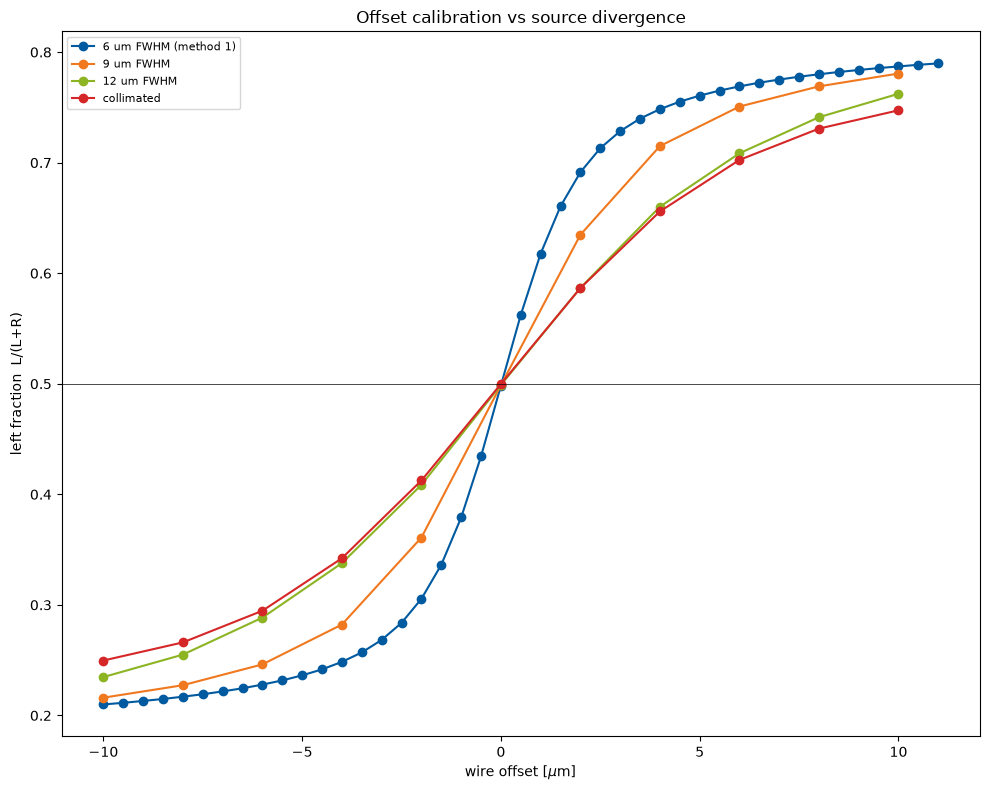

6 um FWHM (method 1)    : slope +0.03750 /um at divergence   16.9 urad
9 um FWHM               : slope +0.03474 /um at divergence   29.9 urad
12 um FWHM              : slope +0.03030 /um at divergence   40.5 urad
collimated              : slope +0.02896 /um at divergence    4.8 urad
divergence/offset data saved as: DivSAXS_divergence_vs_offset_Methods.dat


In [ ]:
# Scan wire position at fixed beam center; changes in the curve then measure
# how source divergence/wavefront curvature changes offset sensitivity.
DIV_OFFSETS = np.linspace(-10, 10, 11)
DIV_CASES = {"9 um FWHM": WAIST_FOR_TARGET_FWHM[9],
             "12 um FWHM": WAIST_FOR_TARGET_FWHM[12],
             "collimated": WAIST_COLLIMATED}
for name, waist in DIV_CASES.items():
    RESULTS[f"div:{name}"] = run_scan(
        [dict(offset_um=o, waist_nm=waist) for o in DIV_OFFSETS], label=f"div {name}")

fig, axs = plt.subplots(figsize=(10, 8))
curves = {f"{TARGET_FWHM / PCI.um:g} um FWHM (method 1)": (off_um, off_frac, WAIST_DEFAULT)}
for name, waist in DIV_CASES.items():
    recs = RESULTS[f"div:{name}"]   # record list for this divergence case
    curves[name] = (np.array([r["offset_um"] for r in recs]),
                    np.array([r["mark1300_frac"] for r in recs]), waist)
slopes, thetas = [], []
for (name, (x, y, waist)), color in zip(curves.items(),
                                        [rofl.b(), rofl.o(), rofl.g(), "tab:red"]):
    axs.plot(x, y, "o-", color=color, label=name)
    slopes.append(np.polyfit(x, y, 1)[0])
    # Gaussian far-field half-angle theta ~= lambda/(pi*w0); waist is w0.
    thetas.append(LAMBDA_NM / (np.pi * waist) * 1e6)  # theta [urad]

# Save every point shown in the divergence/offset calibration plot. Long-form
# rows keep the file unambiguous when cases use different offset grids.
divergence_rows = []
for (name, (x, y, waist)), slope, theta in zip(curves.items(), slopes, thetas):
    divergence_rows.extend(
        (name, offset_um, waist, theta, slope, left_fraction)
        for offset_um, left_fraction in zip(x, y)
    )
divergence_table_path = METHODS_OUTPUT_DIR / "tables" / "DivSAXS_divergence_vs_offset_Methods.dat"
np.savetxt(
    divergence_table_path, np.asarray(divergence_rows, dtype=object), delimiter="\t",
    fmt=("%s", "%.8f", "%.8f", "%.8f", "%.10f", "%.10f"),
    header=("case\toffset_um\tsource_waist_nm\tdivergence_urad\t"
            "calibration_slope_per_um\tleft_fraction"),
)
axs.axhline(0.5, color="k", lw=0.5)
axs.set_xlabel(r"wire offset [$\mu$m]")
axs.set_ylabel("left fraction  L/(L+R)")
axs.legend(fontsize=8)
axs.set_title("Offset calibration vs source divergence")



plt.tight_layout()
plt.savefig(FIG_DIR / "05_divergence_scan.png", dpi=200, bbox_inches="tight")
plt.show()

for name, slope, theta in zip(curves, slopes, thetas):
    print(f"{name:24s}: slope {slope:+.5f} /um at divergence {theta:6.1f} urad")
print(f"divergence/offset data saved as: {divergence_table_path.name}")


## Method 3 — post-sample PCI and clean-SAXS detector gallery

For every configured wire offset, two independent reference-aligned simulations are exported:

In both branches the source remains centered and the positive offset moves the wire center in +x.

1. `DivPCI_AfterSample_Offset*.tif` contains $|E_{\mathrm{exit}}|^2$ immediately
   after the divergent `PCI.gaussian_XFEL` field passes through the voxelized
   `PCI.py` wire. No post-sample propagation is applied.
2. `DivSAXS_Offset*.tif` follows `clean_saxs_design.ipynb`: voxelized wire and the
   Lorentz/Fresnel propagation to the SAXS detector 1.31 m after the sample.

The PCI branch stops at the sample exit; the SAXS branch propagates independently to
its detector. Their common source and voxelized target definitions are constructed
independently in each branch.


In [ ]:
# Gallery/export controls: -10 to +10 um in 2.5 um steps, matching clean_saxs_design.
MOVIE_OFFSETS_UM = np.arange(-10.0, 10.0 + 1.25, 2.5)
SAVE_TIFS = True

MOVIE_DIR = METHODS_OUTPUT_DIR / "movie" / f"{FWHM_TAG}um"
FRAME_DIR = MOVIE_DIR / "frames"
MOVIE_DIR.mkdir(parents=True, exist_ok=True)
FRAME_DIR.mkdir(exist_ok=True)

gif_frames = []
pci_half_width_um = N_GRID * PIXEL_SIZE / (2 * PCI.um)
q_half_width = float(np.abs(Q_AXIS).max())

for frame_index, offset_um in enumerate(MOVIE_OFFSETS_UM):
    rec = run_sim(offset_um=float(offset_um), keep_image=True)
    saxs_detector = rec.pop("saxs_detector_intensity")

    offset_tag = f"{offset_um:.2f}"
    if SAVE_TIFS:
        Image.fromarray(saxs_detector.astype(np.float32)).save(
            MOVIE_DIR / f"DivSAXS_Offset{offset_tag}um.tif",
            format="TIFF", compression="tiff_deflate",
        )
    saxs_max = float(np.nanmax(saxs_detector))
    saxs_step = max(1, N_GRID // 1024)
    saxs_display = saxs_detector[::saxs_step, ::saxs_step].copy()
    del saxs_detector

    # Build the direct post-sample PCI image after SAXS releases its large fields.
    pci_after_sample = pci_exit_intensity(float(offset_um))
    if SAVE_TIFS:
        Image.fromarray(pci_after_sample.astype(np.float32)).save(
            MOVIE_DIR / f"DivPCI_AfterSample_Offset{offset_tag}um.tif",
            format="TIFF", compression="tiff_deflate",
        )
    pci_max = float(np.nanmax(pci_after_sample))
    pci_step = max(1, N_GRID // 1024)
    pci_display = pci_after_sample[::pci_step, ::pci_step].copy()
    del pci_after_sample

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    axes[0].imshow(
        pci_display, origin="lower", cmap=rofl.cmap(),
        extent=[-pci_half_width_um, pci_half_width_um] * 2,
        vmin=0.0, vmax=pci_max,
    )
    axes[0].set(
        xlabel="Sample-plane x [µm]", ylabel="Sample-plane y [µm]",
        title=r"PCI immediately after sample: $|E_{\rm exit}|^2$",
    )

    axes[1].imshow(
        saxs_display, origin="lower", cmap=rofl.cmap(),
        extent=[-q_half_width, q_half_width] * 2,
        norm=LogNorm(vmin=max(saxs_max * 1e-9, np.finfo(float).tiny),
                     vmax=saxs_max),
        aspect="auto",
    )
    axes[1].set(
        xlabel=r"Q$_x$ [1/nm]", ylabel=r"Q$_y$ [1/nm]",
        title="SAXS at detector (log scale)",
    )
    axes[1].set_ylim(-0.08, 0.08)
    fig.suptitle(f"Wire offset {offset_um:+.1f} µm — PCI exit and SAXS detector")
    fig.tight_layout()

    frame_path = FRAME_DIR / f"frame{frame_index:02d}_offset{offset_um:+.1f}um.png"
    fig.savefig(frame_path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    with Image.open(frame_path) as frame:
        gif_frames.append(frame.convert("RGB").copy())

    del pci_display, saxs_display
    print(
        f"[gallery {frame_index + 1}/{len(MOVIE_OFFSETS_UM)}] "
        f"offset {offset_um:+.1f} µm: PCI=after sample, SAXS=detector"
    )

gif_path = MOVIE_DIR / "PCI_after_sample_SAXS_detector_offset_scan.gif"
if gif_frames:
    gif_frames[0].save(
        gif_path, save_all=True, append_images=gif_frames[1:],
        duration=350, loop=0,
    )
print(f"Saved gallery GIF: {gif_path}")
print("PCI TIF plane: immediately after sample; SAXS TIF plane: 1.31 m detector")

Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
[gallery 1/9] offset -10.0 µm: PCI=after sample, SAXS=detector
Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
[gallery 2/9] offset -7.5 µm: PCI=after sample, SAXS=detector
Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


... (9 outputs left out)

"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
[gallery 8/9] offset +7.5 µm: PCI=after sample, SAXS=detector
Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


"Sorry, due to the detector type 'SAXS', bandwidth not taken into account in propagation from last target to detector!"


Rayleigh [m]:  0.16837868596938366
Radius [um]:  363405.5275551053 0.15120024068359483
the beam waist on the target plane is  5.096 um
the FWHM beam waist on the target plane is  6.000 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+168378685.96938363j)
mu is 4.0906392887346616e-05 [1/um]
[gallery 9/9] offset +10.0 µm: PCI=after sample, SAXS=detector
Saved gallery GIF: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\movie\6um\PCI_after_sample_SAXS_detector_offset_scan.gif
PCI TIF plane: immediately after sample; SAXS TIF plane: 1.31 m detector


In [ ]:
total = time.perf_counter() - NOTEBOOK_T0
n_runs = sum(len(v) for v in RESULTS.values()) + len(MOVIE_OFFSETS_UM)
print(f"total wall time: {total / 60:.1f} min for {n_runs} SAXS propagations "
      f"(SAXS and PCI grids {N_GRID})")
print(f"figures saved in: {FIG_DIR}")
print(f"asymmetry table saved as: {methods_table_path} "
      "(legacy 3-column format: offset nm, left, right)")
print(f"divergence/offset table saved as: {divergence_table_path}")


total wall time: 6.3 min for 86 SAXS propagations (SAXS and PCI grids 4096)
figures saved in: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\figures
asymmetry table saved as: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\tables\DivSAXS_asymmetry_Methods_6um.dat (legacy 3-column format: offset nm, left, right)
divergence/offset table saved as: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\tables\DivSAXS_divergence_vs_offset_Methods.dat
